In [11]:
from pathlib import Path
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
TABLES_DIR = PROJECT_DIR / "results" / "tables"
FIGURES_DIR = PROJECT_DIR / "results" / "figures"

TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

edges = pd.read_csv(PROCESSED_DIR / "email_edges_clean.csv")
departments = pd.read_csv(
    PROCESSED_DIR / "email_departments_clean.csv"
)

edges["source"] = edges["source"].astype(int)
edges["target"] = edges["target"].astype(int)
departments["node"] = departments["node"].astype(int)

department_map = departments.set_index("node")["department"].to_dict()

G = nx.Graph()
G.add_edges_from(
    edges[["source", "target"]].itertuples(index=False, name=None)
)
G.add_nodes_from(departments["node"])

nx.set_node_attributes(G, department_map, "department")

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

Nodes: 1005
Edges: 16706


In [12]:
print("Calculating betweenness centrality...")

betweenness = nx.betweenness_centrality(G, normalized=True)
degree = dict(G.degree())

node_rows = []

for node in G.nodes():
    own_department = department_map.get(node)
    neighbors = list(G.neighbors(node))

    known_departments = [
        department_map.get(neighbor)
        for neighbor in neighbors
        if pd.notna(department_map.get(neighbor))
    ]

    cross_count = sum(
        1 for d in known_departments
        if pd.notna(own_department) and d != own_department
    )

    cross_fraction = (
        cross_count / len(known_departments)
        if known_departments else 0
    )

    node_rows.append({
        "node": node,
        "degree": degree[node],
        "betweenness": betweenness[node],
        "cross_department_count": cross_count,
        "cross_department_fraction": cross_fraction
    })

node_scores = pd.DataFrame(node_rows).set_index("node")

# Original department-aware score
node_scores["department_aware_score"] = (
    node_scores["betweenness"]
    * node_scores["cross_department_fraction"]
)

# Combined ranking: average of percentile ranks for both measures.
# Higher values mean higher priority for removal.
node_scores["betweenness_rank_score"] = (
    node_scores["betweenness"].rank(pct=True)
)

node_scores["cross_fraction_rank_score"] = (
    node_scores["cross_department_fraction"].rank(pct=True)
)

node_scores["combined_score"] = (
    node_scores["betweenness_rank_score"]
    + node_scores["cross_fraction_rank_score"]
) / 2

display(
    node_scores.sort_values(
        "combined_score", ascending=False
    ).head(10)
)

Calculating betweenness centrality...


,degree,betweenness,cross_department_count,cross_department_fraction,department_aware_score,betweenness_rank_score,cross_fraction_rank_score,combined_score
node,,,,,,,,
160,347,0.087415,334,0.965318,0.084383,1.000000,0.920398,0.960199
5,171,0.030995,164,0.964706,0.029901,0.998010,0.919403,0.958706
13,180,0.023565,173,0.966480,0.022775,0.994030,0.921393,0.957711
64,170,0.021924,163,0.964497,0.021145,0.991045,0.917413,0.954229
533,157,0.018863,151,0.961783,0.018142,0.989055,0.916418,0.952736
560,55,0.006012,55,1.000000,0.006012,0.940299,0.965174,0.952736
971,97,0.016698,92,0.958333,0.016002,0.986070,0.913433,0.949751
62,216,0.022510,204,0.948837,0.021358,0.992040,0.900498,0.946269
434,185,0.015413,175,0.951087,0.014659,0.985075,0.906468,0.945771


In [13]:
REMOVAL_FRACTIONS = np.linspace(0, 0.50, 11)

def simulate_removal(graph, removal_order, fractions):
    original_n = graph.number_of_nodes()
    rows = []

    for fraction in fractions:
        k = int(round(fraction * original_n))
        removed = set(removal_order[:k])

        remaining = [
            node for node in graph.nodes()
            if node not in removed
        ]

        H = graph.subgraph(remaining)

        if H.number_of_nodes() == 0:
            lcc_size = 0
        else:
            lcc_size = max(
                len(c)
                for c in nx.connected_components(H)
            )

        rows.append({
            "removal_fraction": fraction,
            "removed_nodes": k,
            "largest_component_size": lcc_size,
            "largest_component_fraction": lcc_size / original_n
        })

    return pd.DataFrame(rows)

In [14]:
orders = {
    "Betweenness-based": (
        node_scores["betweenness"]
        .sort_values(ascending=False).index.tolist()
    ),
    "Cross-fraction": (
        node_scores["cross_department_fraction"]
        .sort_values(ascending=False).index.tolist()
    ),
    "Department-aware": (
        node_scores["department_aware_score"]
        .sort_values(ascending=False).index.tolist()
    ),
    "Combined ranking": (
        node_scores["combined_score"]
        .sort_values(ascending=False).index.tolist()
    )
}

robustness_results = []

for strategy, order in orders.items():
    print("Running:", strategy)

    result = simulate_removal(
        G, order, REMOVAL_FRACTIONS
    )
    result["strategy"] = strategy
    robustness_results.append(result)

robustness_df = pd.concat(
    robustness_results,
    ignore_index=True
)

display(robustness_df.head(15))

robustness_df.to_csv(
    TABLES_DIR / "robustness_strategy_results.csv",
    index=False
)

Running: Betweenness-based
Running: Cross-fraction
Running: Department-aware
Running: Combined ranking


,removal_fraction,removed_nodes,largest_component_size,largest_component_fraction,strategy
0,0.00,0,986,0.981095,Betweenness-based
1,0.05,50,896,0.891542,Betweenness-based
2,0.10,100,812,0.807960,Betweenness-based
3,0.15,151,726,0.722388,Betweenness-based
4,0.20,201,638,0.634826,Betweenness-based
5,0.25,251,569,0.566169,Betweenness-based
6,0.30,302,501,0.498507,Betweenness-based
7,0.35,352,424,0.421891,Betweenness-based
8,0.40,402,336,0.334328,Betweenness-based
9,0.45,452,248,0.246766,Betweenness-based


In [15]:
auc_rows = []

for strategy, group in robustness_df.groupby("strategy"):
    group = group.sort_values("removal_fraction")

    auc = np.trapezoid(
        group["largest_component_fraction"],
        group["removal_fraction"]
    )

    auc_rows.append({
        "strategy": strategy,
        "resilience_auc": auc
    })

robustness_auc = pd.DataFrame(auc_rows).sort_values(
    "resilience_auc"
)

display(robustness_auc)

robustness_auc.to_csv(
    TABLES_DIR / "robustness_auc_comparison.csv",
    index=False
)

,strategy,resilience_auc
0,Betweenness-based,0.281493
3,Department-aware,0.283458
1,Combined ranking,0.302065
2,Cross-fraction,0.349950


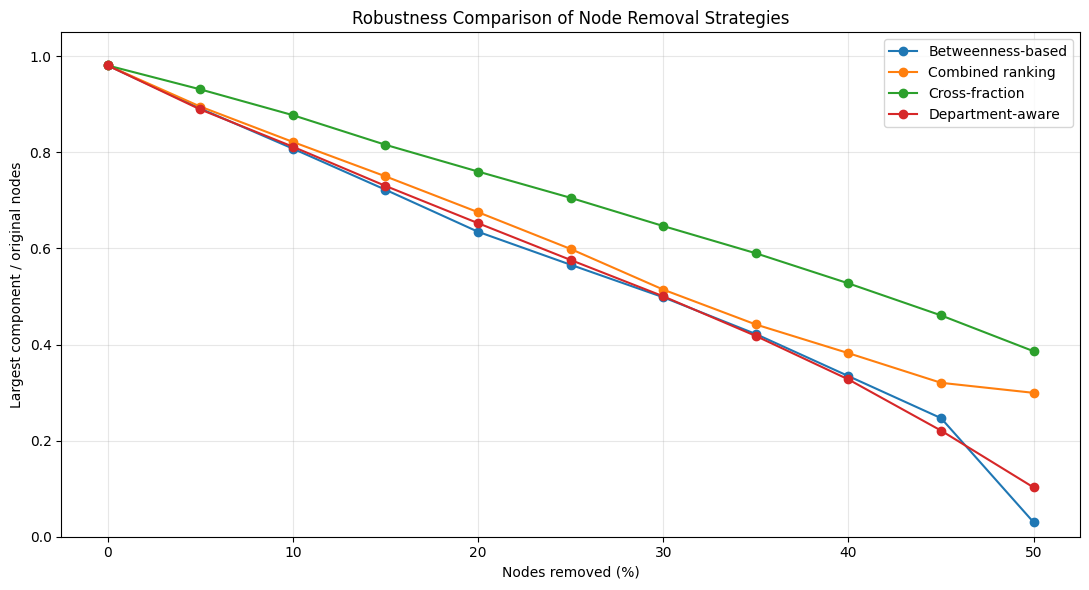

In [16]:
plt.figure(figsize=(11, 6))

for strategy, group in robustness_df.groupby("strategy"):
    group = group.sort_values("removal_fraction")

    plt.plot(
        group["removal_fraction"] * 100,
        group["largest_component_fraction"],
        marker="o",
        label=strategy
    )

plt.xlabel("Nodes removed (%)")
plt.ylabel("Largest component / original nodes")
plt.title("Robustness Comparison of Node Removal Strategies")
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "robustness_strategy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
pivot = robustness_df.pivot(
    index="removal_fraction",
    columns="strategy",
    values="largest_component_fraction"
)

pivot["Department-aware minus Betweenness"] = (
    pivot["Department-aware"] - pivot["Betweenness-based"]
)

pivot["Combined minus Betweenness"] = (
    pivot["Combined ranking"] - pivot["Betweenness-based"]
)

display(pivot)

pivot.to_csv(
    TABLES_DIR / "robustness_difference_analysis.csv"
)

strategy,Betweenness-based,Combined ranking,Cross-fraction,Department-aware,Department-aware minus Betweenness,Combined minus Betweenness
removal_fraction,,,,,,
0.00,0.981095,0.981095,0.981095,0.981095,0.000000,0.000000
0.05,0.891542,0.895522,0.931343,0.889552,-0.001990,0.003980
0.10,0.807960,0.821891,0.877612,0.811940,0.003980,0.013930
0.15,0.722388,0.750249,0.815920,0.730348,0.007960,0.027861
0.20,0.634826,0.675622,0.760199,0.652736,0.017910,0.040796
0.25,0.566169,0.599005,0.705473,0.576119,0.009950,0.032836
0.30,0.498507,0.514428,0.646766,0.500498,0.001990,0.015920
0.35,0.421891,0.441791,0.590050,0.417910,-0.003980,0.019900
0.40,0.334328,0.382090,0.527363,0.327363,-0.006965,0.047761


In [18]:
from pathlib import Path
import pandas as pd

# Find the project results folder
possible_dirs = [
    Path("../results/tables"),
    Path("results/tables"),
    Path.cwd() / "../results/tables",
]

TABLES_DIR = next(
    (p.resolve() for p in possible_dirs if p.resolve().is_dir()),
    None
)

if TABLES_DIR is None:
    print("Results folder not found.")
    print("Current notebook directory:", Path.cwd())
else:
    print("Results folder:", TABLES_DIR)

    print("\nAvailable CSV files:")
    for file in sorted(TABLES_DIR.glob("*.csv")):
        print("-", file.name)

    # Load saved targeted-strategy results
    targeted_file = TABLES_DIR / "robustness_strategy_results.csv"

    if targeted_file.exists():
        robustness_df = pd.read_csv(targeted_file)
        print("\nTargeted results loaded successfully.")
        print("Shape:", robustness_df.shape)
        display(robustness_df.head())
    else:
        print("\nrobustness_strategy_results.csv was not found.")

    # Load saved random-removal trials
    random_file = TABLES_DIR / "random_removal_100_trials.csv"

    if random_file.exists():
        random_all = pd.read_csv(random_file)
        print("\nRandom-removal results loaded successfully.")
        print("Shape:", random_all.shape)
        display(random_all.head())
    else:
        print("\nrandom_removal_100_trials.csv was not found.")

Results folder: C:\Users\ASUS\Documents\GitHub\Communication-Network-Failure-and-Resilience\results\tables

Available CSV files:
- cross_department_edges.csv
- cross_department_pair_counts.csv
- data_validation_summary.csv
- department_bridge_centrality.csv
- department_sizes.csv
- department_vs_betweenness.csv
- graph_basic_statistics.csv
- key_resilience_comparison.csv
- network_resilience_comparison.csv
- node_degree_statistics.csv
- potential_bridge_nodes.csv
- random_auc_100_trials.csv
- random_removal_100_trials.csv
- random_removal_uncertainty.csv
- resilience_auc_comparison.csv
- robustness_auc_comparison.csv
- robustness_difference_analysis.csv
- robustness_strategy_results.csv
- simulation_validation_summary.csv
- validated_auc_comparison.csv

Targeted results loaded successfully.
Shape: (44, 5)


,removal_fraction,removed_nodes,largest_component_size,largest_component_fraction,strategy
0,0.00,0,986,0.981095,Betweenness-based
1,0.05,50,896,0.891542,Betweenness-based
2,0.10,100,812,0.807960,Betweenness-based
3,0.15,151,726,0.722388,Betweenness-based
4,0.20,201,638,0.634826,Betweenness-based



Random-removal results loaded successfully.
Shape: (1100, 5)


,removal_fraction,removed_nodes,largest_component_size,largest_component_fraction,run
0,0.00,0,986,0.981095,1
1,0.05,50,934,0.929353,1
2,0.10,100,883,0.878607,1
3,0.15,151,829,0.824876,1
4,0.20,201,775,0.771144,1


In [20]:
import numpy as np
import pandas as pd

# Use the loaded result files
targeted = robustness_df.copy()

random_file = TABLES_DIR / "random_removal_100_trials.csv"
random_all = pd.read_csv(random_file)

# Check columns
print("Targeted columns:", targeted.columns.tolist())
print("Random columns:", random_all.columns.tolist())

# Calculate AUC for targeted strategies
auc_rows = []

for strategy, group in targeted.groupby("strategy"):
    group = group.sort_values("removal_fraction")

    x = group["removal_fraction"].to_numpy(dtype=float)
    y = group["largest_component_fraction"].to_numpy(dtype=float)

    auc_rows.append({
        "strategy": strategy,
        "mean_auc": np.trapezoid(y, x),
        "std_auc": np.nan,
        "lower_95": np.nan,
        "upper_95": np.nan
    })

# Calculate AUC for every random-removal run
random_auc = []

for run_id, group in random_all.groupby("run"):
    group = group.sort_values("removal_fraction")

    x = group["removal_fraction"].to_numpy(dtype=float)
    y = group["largest_component_fraction"].to_numpy(dtype=float)

    random_auc.append(np.trapezoid(y, x))

random_auc = np.asarray(random_auc)

auc_rows.append({
    "strategy": "Random",
    "mean_auc": random_auc.mean(),
    "std_auc": random_auc.std(ddof=1),
    "lower_95": np.quantile(random_auc, 0.025),
    "upper_95": np.quantile(random_auc, 0.975)
})

# Final table
final_auc_df = pd.DataFrame(auc_rows)
final_auc_df = final_auc_df.sort_values("mean_auc", ascending=False)

display(final_auc_df)

# Save
output_path = TABLES_DIR / "final_consistent_auc_comparison.csv"
final_auc_df.to_csv(output_path, index=False)

print(f"\nSaved final comparison to: {output_path}")
print(f"Random-removal runs: {len(random_auc)}")

Targeted columns: ['removal_fraction', 'removed_nodes', 'largest_component_size', 'largest_component_fraction', 'strategy']
Random columns: ['removal_fraction', 'removed_nodes', 'largest_component_size', 'largest_component_fraction', 'run']


,strategy,mean_auc,std_auc,lower_95,upper_95
4,Random,0.358670,0.001946,0.3551,0.362132
2,Cross-fraction,0.349950,NaN,NaN,NaN
1,Combined ranking,0.302065,NaN,NaN,NaN
3,Department-aware,0.283458,NaN,NaN,NaN
0,Betweenness-based,0.281493,NaN,NaN,NaN



Saved final comparison to: C:\Users\ASUS\Documents\GitHub\Communication-Network-Failure-and-Resilience\results\tables\final_consistent_auc_comparison.csv
Random-removal runs: 100


In [21]:
print("G exists:", "G" in globals())
print("simulate_removal exists:", "simulate_removal" in globals())
print("node_scores exists:", "node_scores" in globals())

G exists: True
simulate_removal exists: True
node_scores exists: True


In [24]:
import numpy as np
import pandas as pd

# 1. Create degree-based removal ranking
degree_order = (
    node_scores["degree"]
    .sort_values(ascending=False)
    .index
    .tolist()
)

# 2. Simulate degree-based removal
degree_result = simulate_removal(
    G,
    degree_order,
    REMOVAL_FRACTIONS
)

# 3. Convert results into a DataFrame
degree_df = pd.DataFrame(degree_result)

degree_df["strategy"] = "Degree-based"

print("Degree-based simulation results:")
display(degree_df.head())

print("Columns:", degree_df.columns.tolist())

Degree-based simulation results:


,removal_fraction,removed_nodes,largest_component_size,largest_component_fraction,strategy
0,0.00,0,986,0.981095,Degree-based
1,0.05,50,909,0.904478,Degree-based
2,0.10,100,832,0.827861,Degree-based
3,0.15,151,757,0.753234,Degree-based
4,0.20,201,678,0.674627,Degree-based


Columns: ['removal_fraction', 'removed_nodes', 'largest_component_size', 'largest_component_fraction', 'strategy']


In [23]:
# Add Degree-based results to targeted results
targeted_updated = pd.concat(
    [robustness_df, degree_df],
    ignore_index=True
)

auc_rows = []

for strategy, group in targeted_updated.groupby("strategy"):
    group = group.sort_values("removal_fraction")

    x = group["removal_fraction"].to_numpy(dtype=float)
    y = group["largest_component_fraction"].to_numpy(dtype=float)

    auc_rows.append({
        "strategy": strategy,
        "mean_auc": np.trapezoid(y, x),
        "std_auc": np.nan,
        "lower_95": np.nan,
        "upper_95": np.nan
    })

# Add Random strategy using 100 trials
random_auc = []

for run_id, group in random_all.groupby("run"):
    group = group.sort_values("removal_fraction")

    x = group["removal_fraction"].to_numpy(dtype=float)
    y = group["largest_component_fraction"].to_numpy(dtype=float)

    random_auc.append(np.trapezoid(y, x))

random_auc = np.asarray(random_auc)

auc_rows.append({
    "strategy": "Random",
    "mean_auc": random_auc.mean(),
    "std_auc": random_auc.std(ddof=1),
    "lower_95": np.quantile(random_auc, 0.025),
    "upper_95": np.quantile(random_auc, 0.975)
})

# Final comparison
final_auc_df = (
    pd.DataFrame(auc_rows)
    .sort_values("mean_auc", ascending=False)
    .reset_index(drop=True)
)

display(final_auc_df)

# Save final results
output_path = TABLES_DIR / "final_consistent_auc_comparison.csv"
final_auc_df.to_csv(output_path, index=False)

print(f"Saved final results to: {output_path}")

,strategy,mean_auc,std_auc,lower_95,upper_95
0,Random,0.358670,0.001946,0.3551,0.362132
1,Cross-fraction,0.349950,NaN,NaN,NaN
2,Combined ranking,0.302065,NaN,NaN,NaN
3,Degree-based,0.298682,NaN,NaN,NaN
4,Department-aware,0.283458,NaN,NaN,NaN
5,Betweenness-based,0.281493,NaN,NaN,NaN


Saved final results to: C:\Users\ASUS\Documents\GitHub\Communication-Network-Failure-and-Resilience\results\tables\final_consistent_auc_comparison.csv


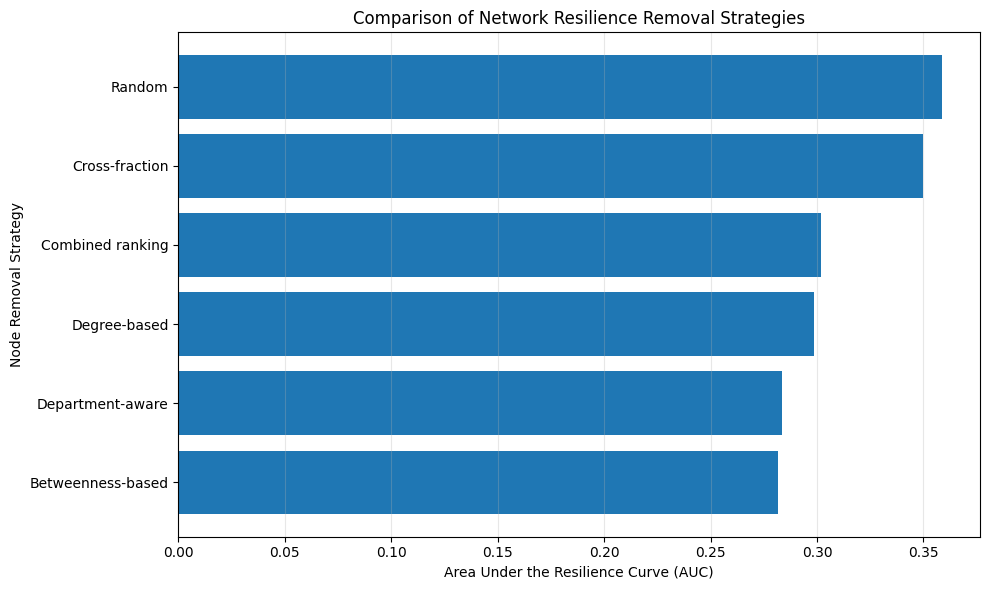

Figure saved to: ..\results\figures\final_auc_comparison.png


In [25]:
import matplotlib.pyplot as plt
from pathlib import Path

# Create figure output directory
FIGURES_DIR = Path("../results/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Sort strategies from lowest to highest AUC
plot_df = final_auc_df.sort_values("mean_auc", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(plot_df["strategy"], plot_df["mean_auc"])

plt.xlabel("Area Under the Resilience Curve (AUC)")
plt.ylabel("Node Removal Strategy")
plt.title("Comparison of Network Resilience Removal Strategies")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

# Save figure
figure_path = FIGURES_DIR / "final_auc_comparison.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {figure_path}")

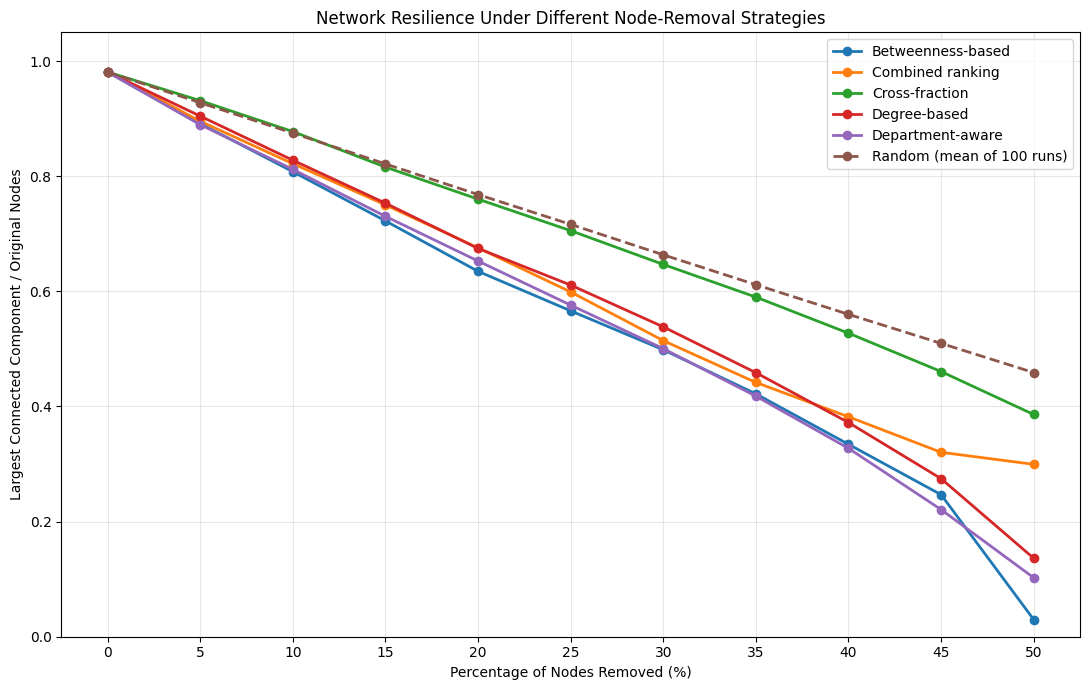

Resilience curves saved to: ..\results\figures\final_resilience_curves.png


In [26]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# Create output directory
FIGURES_DIR = Path("../results/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Include all targeted strategies, including Degree-based
targeted_plot = targeted_updated.copy()

# Calculate mean LCC fraction for random trials at each removal level
random_mean = (
    random_all
    .groupby("removal_fraction", as_index=False)
    ["largest_component_fraction"]
    .mean()
)

# Plot resilience curves
plt.figure(figsize=(11, 7))

for strategy, group in targeted_plot.groupby("strategy"):
    group = group.sort_values("removal_fraction")

    plt.plot(
        group["removal_fraction"] * 100,
        group["largest_component_fraction"],
        marker="o",
        linewidth=2,
        label=strategy
    )

# Add random baseline
random_mean = random_mean.sort_values("removal_fraction")

plt.plot(
    random_mean["removal_fraction"] * 100,
    random_mean["largest_component_fraction"],
    marker="o",
    linestyle="--",
    linewidth=2,
    label="Random (mean of 100 runs)"
)

plt.xlabel("Percentage of Nodes Removed (%)")
plt.ylabel("Largest Connected Component / Original Nodes")
plt.title("Network Resilience Under Different Node-Removal Strategies")
plt.xticks(range(0, 51, 5))
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# Save figure
figure_path = FIGURES_DIR / "final_resilience_curves.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Resilience curves saved to: {figure_path}")